# ML Lab Test — End-to-End Pipeline: Mobile Phone Price Prediction
**Task type:** Regression (target = `Price ($)`, a continuous value)

**Pipeline:** Dataset → EDA/Preprocessing → Train-Test Split → Scaling/Encoding → Model → Hyperparameter Tuning (GridSearchCV) → 5-Fold CV → Evaluation → Final Output

**Experiments**
1. Decision Tree **without PCA**
2. Decision Tree **with PCA**
3. A second algorithm (Random Forest) for comparison
4. Statistical significance test between models
5. (Bonus) Classification version (price tier) to cover imbalance + classification metrics

> Put `Mobile phone price.csv` in the same folder as this notebook (or change `DATA_PATH`).

## 0. Imports & setup

In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, GridSearchCV, KFold,
                                     cross_val_score, RepeatedKFold, StratifiedKFold)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             classification_report, confusion_matrix, accuracy_score)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42
DATA_PATH = 'Mobile phone price.csv'

## 1. Dataset specification

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()      # column names have trailing spaces
print('Shape (rows, cols):', df_raw.shape)
df_raw.head()

Shape (rows, cols): (407, 8)


,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($)
0,Apple,iPhone 13 Pro,128 GB,6 GB,6.1,12 + 12 + 12,3095,999
1,Samsung,Galaxy S21 Ultra,256 GB,12 GB,6.8,108 + 10 + 10 + 12,5000,1199
2,OnePlus,9 Pro,128 GB,8 GB,6.7,48 + 50 + 8 + 2,4500,899
3,Xiaomi,Redmi Note 10 Pro,128 GB,6 GB,6.67,64 + 8 + 5 + 2,5020,279
4,Google,Pixel 6,128 GB,8 GB,6.4,50 + 12.2,4614,799


In [3]:
print(df_raw.dtypes)
print('\nMissing values:\n', df_raw.isna().sum())
print('\nDuplicate rows:', df_raw.duplicated().sum())

Brand                       str
Model                       str
Storage                     str
RAM                         str
Screen Size (inches)        str
Camera (MP)                 str
Battery Capacity (mAh)    int64
Price ($)                   str
dtype: object

Missing values:
 Brand                     0
Model                     0
Storage                   0
RAM                       0
Screen Size (inches)      0
Camera (MP)               0
Battery Capacity (mAh)    0
Price ($)                 0
dtype: int64

Duplicate rows: 26


**Dataset specification**
- ~407 rows × 8 columns: `Brand, Model, Storage, RAM, Screen Size (inches), Camera (MP), Battery Capacity (mAh), Price ($)`
- **Target:** `Price ($)` → continuous → **Regression**
- **Data types:** only Battery is numeric; Storage, RAM, Screen, Camera and Price are stored as *text* with inconsistent formats ("128 GB", "128GB", "128"; "$1,199 ", "1049"; "12MP + 12MP"; "6.8 + 3.9"; "7.6 (unfolded)"). They must be cleaned.
- **Missing values:** none, but there are duplicate rows, which we remove.
- **Categorical:** Brand (and Model – too many unique values, dropped). **Numerical (after cleaning):** Storage, RAM, Screen, Camera features, Battery.
- **Balanced/imbalanced:** not applicable for regression; checked via target distribution in EDA (and via price tiers in the classification bonus).

## 2. Preprocessing / cleaning

In [4]:
def first_number(s):
    m = re.search(r'\d+\.?\d*', str(s))
    return float(m.group()) if m else np.nan

def camera_features(s):
    # keep only real megapixel numbers (ignores tokens like 3D, ToF)
    nums = [float(x) for x in re.findall(r'\d+\.?\d*', str(s).replace('3D','').replace('ToF',''))]
    nums = [n for n in nums if n >= 1]          # drop stray values like 0.3
    return pd.Series({'Main_Camera_MP': nums[0], 'Num_Cameras': len(nums), 'Total_Camera_MP': sum(nums)})

df = df_raw.copy()
df['Storage_GB'] = df['Storage'].apply(first_number)
df['RAM_GB']     = df['RAM'].apply(first_number)
df['Screen_in']  = df['Screen Size (inches)'].apply(first_number)   # foldables: main screen
df['Price']      = df['Price ($)'].astype(str).str.replace(r'[\$,\s]', '', regex=True).astype(float)
df = pd.concat([df, df['Camera (MP)'].apply(camera_features)], axis=1)
df['Battery_mAh'] = df['Battery Capacity (mAh)']
df['Brand'] = df['Brand'].str.strip()

df = df[['Brand','Storage_GB','RAM_GB','Screen_in','Main_Camera_MP','Num_Cameras',
         'Total_Camera_MP','Battery_mAh','Price']]
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {before-len(df)} duplicate rows -> {df.shape}')
print('Missing after cleaning:', df.isna().sum().sum())
df.head()

Removed 73 duplicate rows -> (334, 9)
Missing after cleaning: 0


,Brand,Storage_GB,RAM_GB,Screen_in,Main_Camera_MP,Num_Cameras,Total_Camera_MP,Battery_mAh,Price
0,Apple,128.0,6.0,6.10,12.0,3.0,36.0,3095,999.0
1,Samsung,256.0,12.0,6.80,108.0,4.0,140.0,5000,1199.0
2,OnePlus,128.0,8.0,6.70,48.0,4.0,108.0,4500,899.0
3,Xiaomi,128.0,6.0,6.67,64.0,4.0,79.0,5020,279.0
4,Google,128.0,8.0,6.40,50.0,2.0,62.2,4614,799.0


## 3. EDA

In [5]:
print('Shape:', df.shape)
print('\nData types:\n', df.dtypes)
print('\nMissing values:', df.isna().sum().sum())
df.describe().T

Shape: (334, 9)

Data types:
 Brand                  str
Storage_GB         float64
RAM_GB             float64
Screen_in          float64
Main_Camera_MP     float64
Num_Cameras        float64
Total_Camera_MP    float64
Battery_mAh          int64
Price              float64
dtype: object

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
Storage_GB,334.0,124.455090,68.746539,32.0,64.00,128.0,128.0,512.0
RAM_GB,334.0,5.877246,2.499229,2.0,4.00,6.0,8.0,16.0
Screen_in,334.0,6.483772,0.295436,4.5,6.44,6.5,6.6,7.6
Main_Camera_MP,334.0,42.882036,24.681045,8.0,13.00,48.0,60.5,108.0
Num_Cameras,334.0,3.110778,0.745157,1.0,3.00,3.0,4.0,4.0
Total_Camera_MP,334.0,56.819760,30.946506,8.0,25.00,58.0,76.0,168.0
Battery_mAh,334.0,4701.958084,778.489334,1821.0,4300.00,5000.0,5000.0,7000.0
Price,334.0,410.979042,311.958518,99.0,199.00,284.0,499.0,1999.0


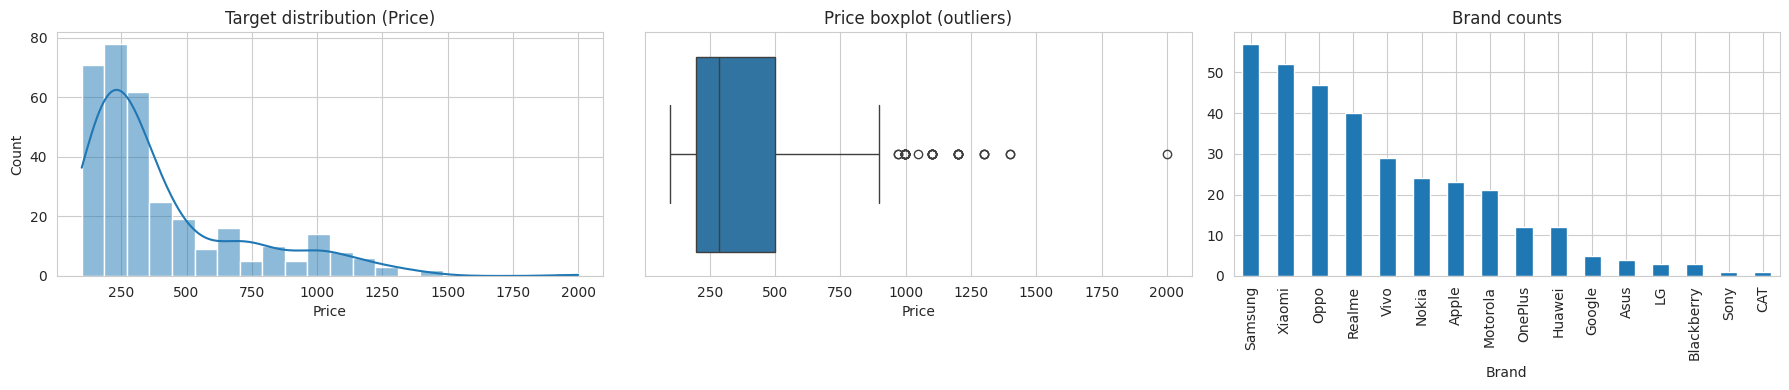

Price skewness: 1.61


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df['Price'], kde=True, ax=ax[0]); ax[0].set_title('Target distribution (Price)')
sns.boxplot(x=df['Price'], ax=ax[1]); ax[1].set_title('Price boxplot (outliers)')
df['Brand'].value_counts().plot(kind='bar', ax=ax[2]); ax[2].set_title('Brand counts')
plt.tight_layout(); plt.show()
print('Price skewness:', round(df['Price'].skew(), 2))

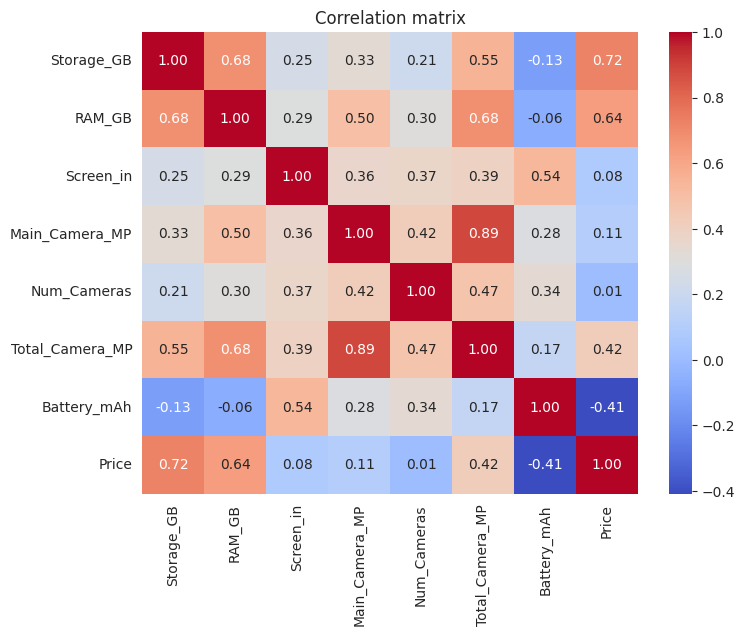

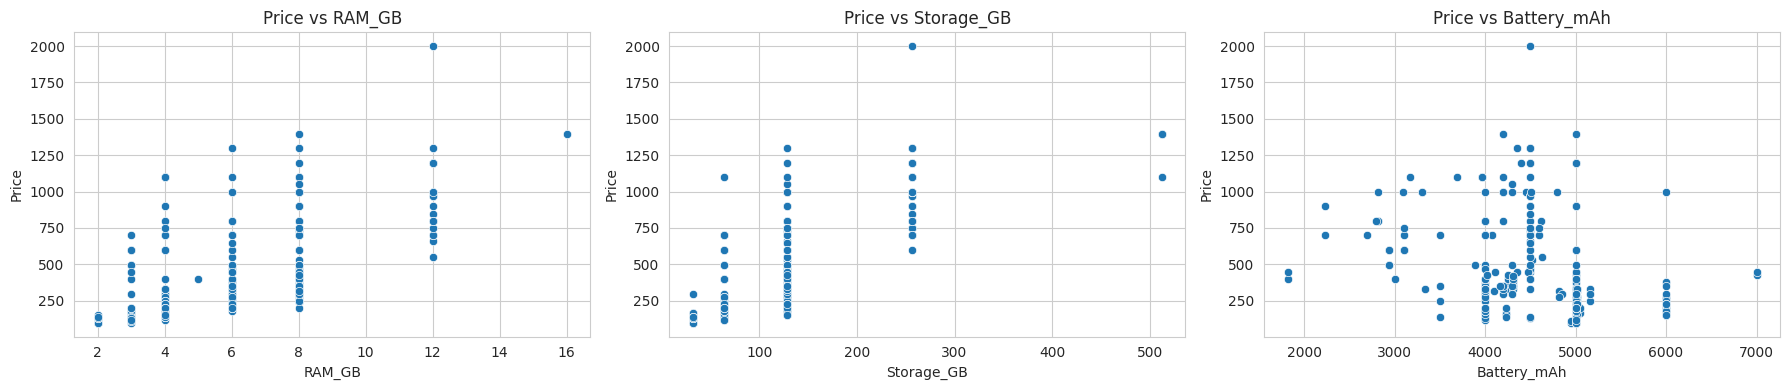

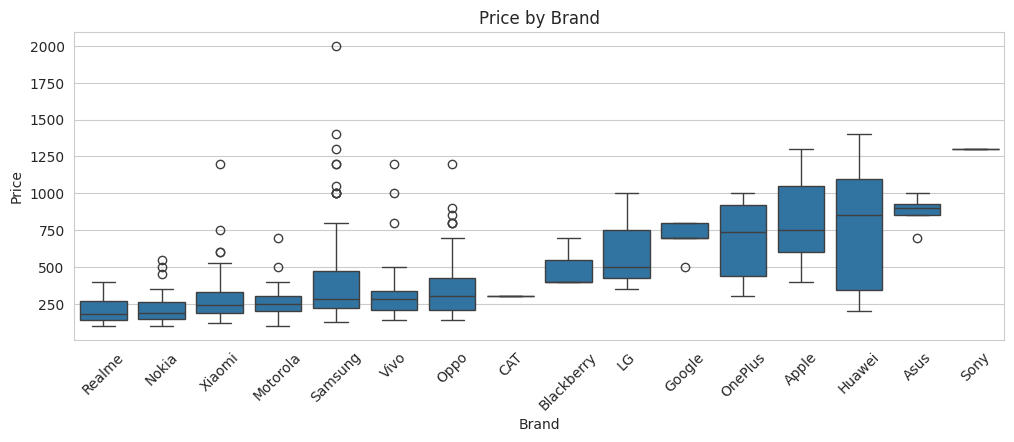

In [7]:
num_cols = ['Storage_GB','RAM_GB','Screen_in','Main_Camera_MP','Num_Cameras','Total_Camera_MP','Battery_mAh']
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols+['Price']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, c in zip(ax, ['RAM_GB','Storage_GB','Battery_mAh']):
    sns.scatterplot(data=df, x=c, y='Price', ax=a); a.set_title(f'Price vs {c}')
plt.tight_layout(); plt.show()

plt.figure(figsize=(12,4))
order = df.groupby('Brand')['Price'].median().sort_values().index
sns.boxplot(data=df, x='Brand', y='Price', order=order); plt.xticks(rotation=45); plt.title('Price by Brand'); plt.show()

**EDA summary (3–4 lines)**
- Price is right-skewed with a few expensive outliers (flagships/foldables); no missing values.
- Price correlates most strongly with **RAM** and **Storage** (higher-end specs), and also varies strongly by **Brand** (Apple/Samsung flagships vs budget brands).
- Battery and screen size have weaker linear relationships with price; the camera features are only moderately related.
- The relationships are partly non-linear, so tree-based models are a reasonable choice.

## 4. Train-test split + preprocessing (scaling & encoding)

In [8]:
X = df.drop(columns='Price')
y = df['Price']
cat_cols = ['Brand']
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

# Scaling + One-hot encoding (inside a pipeline => no data leakage during CV)
def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

prep = make_preprocessor().fit(X_train)
print('Features after encoding:', prep.transform(X_train).shape[1])

Train: (267, 8)  Test: (67, 8)
Features after encoding: 22


## 5. Model 1 — Decision Tree WITHOUT PCA
Pipeline: Preprocess → DecisionTreeRegressor. Hyperparameters tuned with **GridSearchCV (cv=5)** (the grid is small, so an exhaustive grid is affordable).

Key hyperparameters: `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion`.

In [9]:
pipe_dt = Pipeline([('prep', make_preprocessor()),
                    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))])

param_dt = {
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['squared_error', 'absolute_error']
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs_dt = GridSearchCV(pipe_dt, param_dt, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_dt.fit(X_train, y_train)
print('Best params:', gs_dt.best_params_)
print('Best CV RMSE (validation):', round(-gs_dt.best_score_, 2))

Best params: {'model__criterion': 'squared_error', 'model__max_depth': 7, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best CV RMSE (validation): 153.16


## 6. Model 2 — Decision Tree WITH PCA
Pipeline: Preprocess → **PCA** → DecisionTreeRegressor. PCA is a dimensionality-reduction technique that projects the features onto fewer orthogonal components retaining maximum variance. `n_components` is tuned as a hyperparameter. First, look at the explained variance.

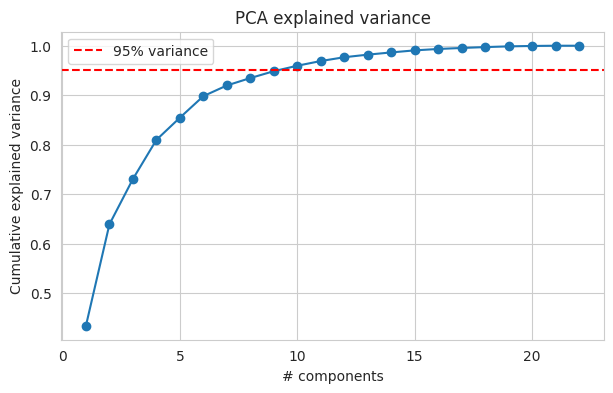

Components for 95% variance: 10 of 22


In [10]:
pca_full = PCA().fit(prep.transform(X_train))
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7,4)); plt.plot(range(1, len(cum)+1), cum, marker='o')
plt.axhline(0.95, color='r', ls='--', label='95% variance'); plt.xlabel('# components'); plt.ylabel('Cumulative explained variance')
plt.title('PCA explained variance'); plt.legend(); plt.show()
print('Components for 95% variance:', int(np.argmax(cum >= 0.95)) + 1, 'of', len(cum))

In [11]:
pipe_pca = Pipeline([('prep', make_preprocessor()),
                     ('pca', PCA(random_state=RANDOM_STATE)),
                     ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))])

param_pca = {'pca__n_components': [3, 5, 8, 10, 15],
             **param_dt}

gs_pca = GridSearchCV(pipe_pca, param_pca, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_pca.fit(X_train, y_train)
print('Best params:', gs_pca.best_params_)
print('Best CV RMSE (validation):', round(-gs_pca.best_score_, 2))

Best params: {'model__criterion': 'absolute_error', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20, 'pca__n_components': 3}
Best CV RMSE (validation): 151.45


## 7. Model 3 — Random Forest (second algorithm for comparison)

In [12]:
pipe_rf = Pipeline([('prep', make_preprocessor()),
                    ('model', RandomForestRegressor(random_state=RANDOM_STATE))])
param_rf = {'model__n_estimators': [100, 200, 300],
            'model__max_depth': [5, 10, None],
            'model__min_samples_leaf': [1, 2, 5],
            'model__max_features': ['sqrt', 1.0]}
# RandomizedSearchCV is shown as the cheaper alternative for larger grids
from sklearn.model_selection import RandomizedSearchCV
gs_rf = RandomizedSearchCV(pipe_rf, param_rf, n_iter=15, cv=kf, scoring='neg_root_mean_squared_error',
                           n_jobs=-1, random_state=RANDOM_STATE)
gs_rf.fit(X_train, y_train)
print('Best params:', gs_rf.best_params_)
print('Best CV RMSE (validation):', round(-gs_rf.best_score_, 2))

Best params: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 10}
Best CV RMSE (validation): 110.36


## 8. 5-Fold Cross-Validation (best models)
Dataset → 5 folds → train on 4, validate on 1 → repeat 5× → **mean score**. We report the mean over folds, not a single split.
CV is run on the **full dataset** with the tuned models (the pipeline refits preprocessing/PCA inside each fold).

In [13]:
from sklearn.base import clone
best_models = {'DecisionTree (no PCA)': gs_dt.best_estimator_,
               'DecisionTree + PCA':    gs_pca.best_estimator_,
               'RandomForest':          gs_rf.best_estimator_}

cv_r2, cv_rmse = {}, {}
for name, m in best_models.items():
    cv_r2[name]   = cross_val_score(clone(m), X, y, cv=kf, scoring='r2')
    cv_rmse[name] = -cross_val_score(clone(m), X, y, cv=kf, scoring='neg_root_mean_squared_error')

cv_table = pd.DataFrame({
    'Mean 5-fold R2':   {k: v.mean() for k, v in cv_r2.items()},
    'Std R2':           {k: v.std()  for k, v in cv_r2.items()},
    'Mean 5-fold RMSE': {k: v.mean() for k, v in cv_rmse.items()},
}).round(3)
print('Per-fold R2:')
for k, v in cv_r2.items(): print(f'  {k:24s}', np.round(v, 3))
cv_table

Per-fold R2:
  DecisionTree (no PCA)    [0.843 0.756 0.732 0.838 0.768]
  DecisionTree + PCA       [0.555 0.691 0.667 0.676 0.628]
  RandomForest             [0.829 0.874 0.881 0.903 0.848]


,Mean 5-fold R2,Std R2,Mean 5-fold RMSE
DecisionTree (no PCA),0.787,0.045,140.420
DecisionTree + PCA,0.644,0.049,184.444
RandomForest,0.867,0.026,112.605


## 9. Final evaluation on the held-out test set

In [14]:
rows = []
preds = {}
for name, m in best_models.items():
    p = m.predict(X_test); preds[name] = p
    mse = mean_squared_error(y_test, p)
    rows.append({'Model': name, 'MAE': mean_absolute_error(y_test, p), 'MSE': mse,
                 'RMSE': np.sqrt(mse), 'R2': r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,MAE,MSE,RMSE,R2
Model,,,,
DecisionTree (no PCA),71.339,18482.943,135.952,0.843
DecisionTree + PCA,115.366,52185.825,228.442,0.555
RandomForest,72.738,21209.173,145.634,0.819


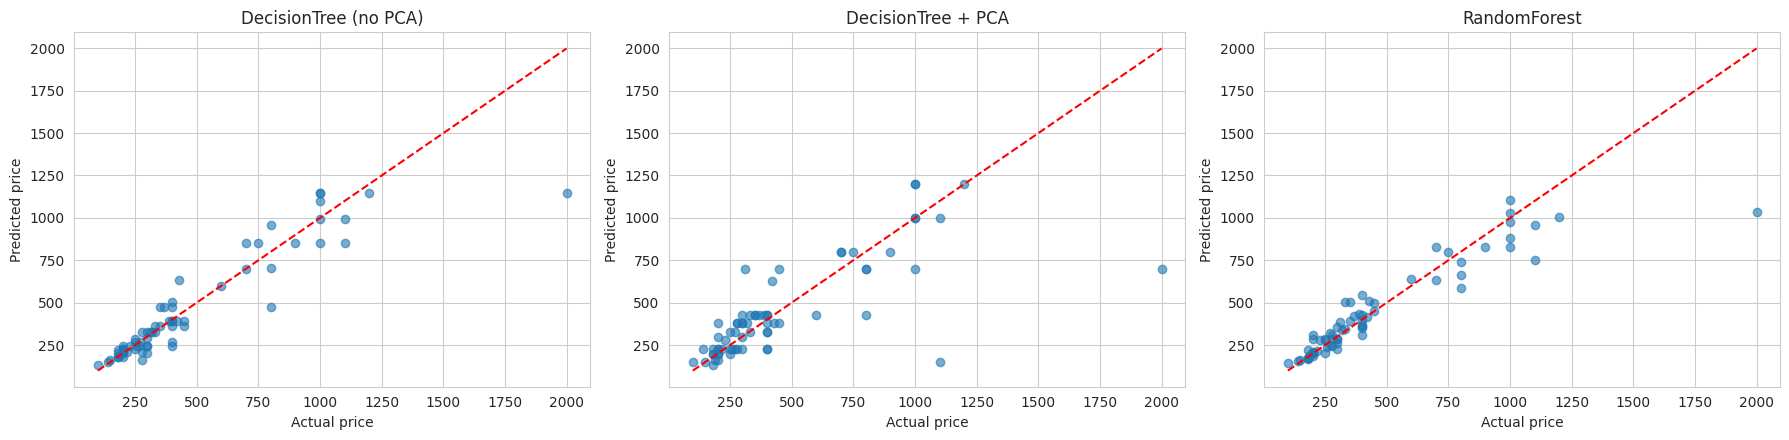

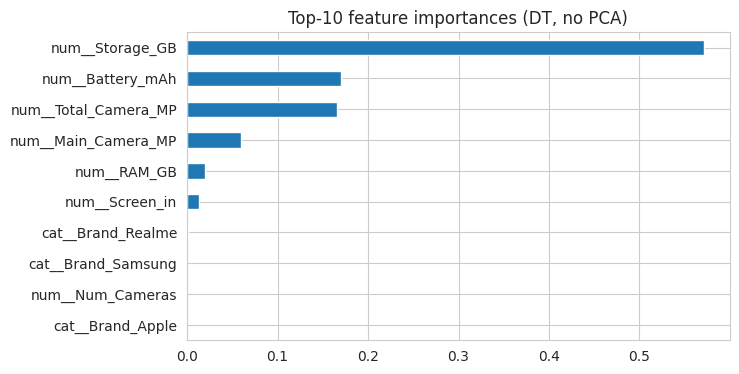

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, alpha=0.6); lim = [y_test.min(), y_test.max()]
    a.plot(lim, lim, 'r--'); a.set_xlabel('Actual price'); a.set_ylabel('Predicted price'); a.set_title(name)
plt.tight_layout(); plt.show()

# Feature importance of the tuned Decision Tree (no PCA)
dt_best = gs_dt.best_estimator_
names = dt_best.named_steps['prep'].get_feature_names_out()
imp = pd.Series(dt_best.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(10)
imp.plot(kind='barh', figsize=(7,4)).invert_yaxis(); plt.title('Top-10 feature importances (DT, no PCA)'); plt.show()

## 10. Statistical significance
Higher mean score ≠ statistically significant. We compare models using the **same CV folds** (paired) and test whether the difference in per-fold scores is likely real.
- Use **repeated 5-fold CV (5×5 = 25 paired scores)** to get enough samples.
- **Paired t-test** (and Wilcoxon signed-rank as a non-parametric check). H0: both models have equal performance. If **p < 0.05**, reject H0.
- Note: scores from overlapping CV folds are not fully independent, so the t-test is slightly optimistic; the corrected resampled t-test (Nadeau–Bengio) is also given.

In [16]:
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
rep = {name: cross_val_score(clone(m), X, y, cv=rkf, scoring='r2') for name, m in best_models.items()}
n_train, n_test = 0.8, 0.2   # fold proportions (5-fold)

def compare(a, b):
    d = rep[a] - rep[b]
    t, p = stats.ttest_rel(rep[a], rep[b])
    try: w_p = stats.wilcoxon(rep[a], rep[b]).pvalue
    except ValueError: w_p = np.nan
    # Nadeau-Bengio corrected resampled t-test
    k = len(d); var = d.var(ddof=1)
    t_c = d.mean() / np.sqrt((1/k + n_test/n_train) * var) if var > 0 else np.nan
    p_c = 2 * stats.t.sf(abs(t_c), k-1) if var > 0 else np.nan
    return {'Comparison': f'{a} vs {b}', 'Mean R2 diff': d.mean(), 't-test p': p,
            'Wilcoxon p': w_p, 'Corrected t-test p': p_c,
            'Significant (p<0.05, corrected)': bool(p_c < 0.05)}

names_ = list(best_models)
sig = pd.DataFrame([compare(names_[0], names_[1]), compare(names_[0], names_[2]), compare(names_[1], names_[2])])
sig.round(4)

,Comparison,Mean R2 diff,t-test p,Wilcoxon p,Corrected t-test p,"Significant (p<0.05, corrected)"
0,DecisionTree (no PCA) vs DecisionTree + PCA,0.1493,0.0,0.0,0.0550,False
1,DecisionTree (no PCA) vs RandomForest,-0.1075,0.0,0.0,0.0155,True
2,DecisionTree + PCA vs RandomForest,-0.2569,0.0,0.0,0.0013,True


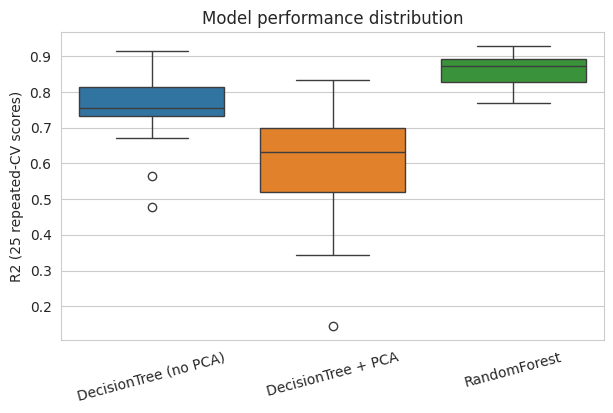

In [17]:
plt.figure(figsize=(7,4)); sns.boxplot(data=pd.DataFrame(rep)); plt.ylabel('R2 (25 repeated-CV scores)')
plt.xticks(rotation=15); plt.title('Model performance distribution'); plt.show()

## 11. (Bonus) Classification version — price tier, imbalance check
Converting price into classes lets us show the classification metrics from the instructions (accuracy, precision, recall, F1, confusion matrix) and an **imbalance check**. Tiers: Budget (< $300), Mid ($300–$699), Premium (≥ $700).

Price
Budget     184
Mid         96
Premium     54
Name: count, dtype: int64
Price
Budget     55.1
Mid        28.7
Premium    16.2
Name: proportion, dtype: float64


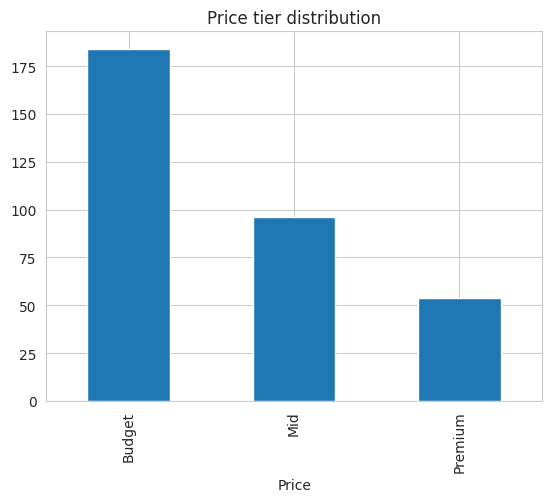

Imbalance ratio (majority/minority): 3.41  -> imbalanced: prefer F1/recall + class_weight


In [18]:
tier = pd.cut(df['Price'], bins=[0, 299, 699, np.inf], labels=['Budget','Mid','Premium'])
print(tier.value_counts()); print((tier.value_counts(normalize=True)*100).round(1))
tier.value_counts().plot(kind='bar', title='Price tier distribution'); plt.show()
ratio = tier.value_counts().max() / tier.value_counts().min()
print(f'Imbalance ratio (majority/minority): {ratio:.2f}  ->', 'imbalanced: prefer F1/recall + class_weight' if ratio > 1.5 else 'roughly balanced')

Best params: {'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 2}
5-fold CV accuracy per fold: [0.761 0.851 0.821 0.821 0.879] | MEAN: 0.827

Test accuracy: 0.791
              precision    recall  f1-score   support

      Budget       0.94      0.78      0.85        37
         Mid       0.60      0.79      0.68        19
     Premium       0.82      0.82      0.82        11

    accuracy                           0.79        67
   macro avg       0.78      0.80      0.78        67
weighted avg       0.82      0.79      0.80        67



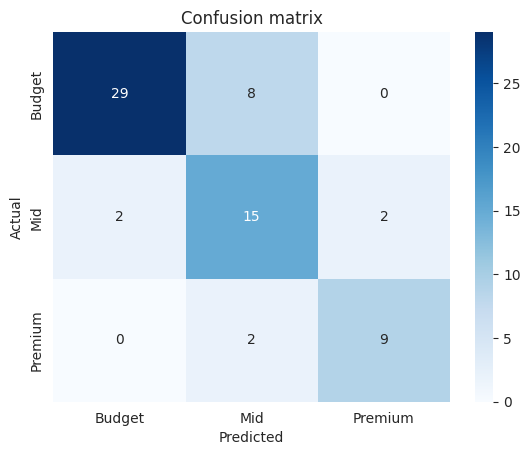

In [19]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, tier, test_size=0.2, stratify=tier, random_state=RANDOM_STATE)
pipe_c = Pipeline([('prep', make_preprocessor()),
                   ('model', DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'))])
grid_c = {'model__max_depth': [3, 5, 7, 10, None], 'model__min_samples_leaf': [1, 2, 5, 10],
          'model__criterion': ['gini', 'entropy']}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, grid_c, cv=skf, scoring='f1_macro', n_jobs=-1).fit(Xc_train, yc_train)
print('Best params:', gs_c.best_params_)
cv_acc = cross_val_score(clone(gs_c.best_estimator_), X, tier, cv=skf, scoring='accuracy')
print('5-fold CV accuracy per fold:', cv_acc.round(3), '| MEAN:', cv_acc.mean().round(3))

yc_pred = gs_c.predict(Xc_test)
print('\nTest accuracy:', round(accuracy_score(yc_test, yc_pred), 3))
print(classification_report(yc_test, yc_pred))
sns.heatmap(confusion_matrix(yc_test, yc_pred, labels=['Budget','Mid','Premium']), annot=True, fmt='d',
            xticklabels=['Budget','Mid','Premium'], yticklabels=['Budget','Mid','Premium'], cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix'); plt.show()

## 12. Final output summary

In [20]:
print('=== BEST HYPERPARAMETERS ===')
print('DT (no PCA):', gs_dt.best_params_)
print('DT + PCA   :', gs_pca.best_params_)
print('RandomForest:', gs_rf.best_params_)
print('\n=== MEAN 5-FOLD CV (full data) ===')
display(cv_table)
print('=== TEST SET METRICS ===')
display(results)
print('=== STATISTICAL SIGNIFICANCE (paired, repeated CV on R2) ===')
display(sig.round(4))
best = cv_table['Mean 5-fold R2'].idxmax()
print(f'\nBest model by mean 5-fold CV R2: {best}')

=== BEST HYPERPARAMETERS ===
DT (no PCA): {'model__criterion': 'squared_error', 'model__max_depth': 7, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
DT + PCA   : {'model__criterion': 'absolute_error', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20, 'pca__n_components': 3}
RandomForest: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 10}

=== MEAN 5-FOLD CV (full data) ===


,Mean 5-fold R2,Std R2,Mean 5-fold RMSE
DecisionTree (no PCA),0.787,0.045,140.420
DecisionTree + PCA,0.644,0.049,184.444
RandomForest,0.867,0.026,112.605


=== TEST SET METRICS ===


,MAE,MSE,RMSE,R2
Model,,,,
DecisionTree (no PCA),71.339,18482.943,135.952,0.843
DecisionTree + PCA,115.366,52185.825,228.442,0.555
RandomForest,72.738,21209.173,145.634,0.819


=== STATISTICAL SIGNIFICANCE (paired, repeated CV on R2) ===


,Comparison,Mean R2 diff,t-test p,Wilcoxon p,Corrected t-test p,"Significant (p<0.05, corrected)"
0,DecisionTree (no PCA) vs DecisionTree + PCA,0.1493,0.0,0.0,0.0550,False
1,DecisionTree (no PCA) vs RandomForest,-0.1075,0.0,0.0,0.0155,True
2,DecisionTree + PCA vs RandomForest,-0.2569,0.0,0.0,0.0013,True



Best model by mean 5-fold CV R2: RandomForest


### Interpretation template (fill in from your output)
- **Input:** cleaned features (Brand, Storage, RAM, Screen, Camera features, Battery) → **Intermediate:** scaling + one-hot → (PCA) → Decision Tree → GridSearchCV → 5-fold CV → **Output:** predicted price + MAE/RMSE/R² + best parameters.
- **PCA vs no PCA:** compare mean CV R² and the significance table. If p ≥ 0.05, PCA's difference is *not* statistically significant, so the simpler model without PCA is preferred (trees do not need scaling/PCA, and PCA makes them harder to interpret).
- **Significance** is claimed only from the p-value, never from a higher accuracy/R² alone.